<a href="https://colab.research.google.com/github/loudamn78-gif/thakaa-flow-training/blob/main/week3/day17/day17.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Telco Customer Churn Analysis
- 🔗 **التطبيق المنشور (Dashboard):** https://telco-churn-dashboard-qtni3o5zrz4jcrbfhdwyys.streamlit.app/


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# إعدادات عرض البيانات
pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid")

print("Libraries imported successfully")

Libraries imported successfully


In [4]:
from google.colab import files

uploaded = files.upload()

### إعداد البيئة وتحميل البيانات

في البداية قمت باستيراد المكتبات اللازمة لتحليل البيانات وعرض النتائج، ثم تم تحميل ملف **Telco-Customer-Churn.csv** للتعرف على محتواه والبدء في تحليل بيانات العملاء ودراسة أسباب تسربهم من الخدمة.

# رحلة تحليل بيانات عملاء الاتصالات (Telco Customer Churn)

## 1. فهم المشكلة (Problem Understanding)
- **السؤال الأساسي:** من هم العملاء الأكثر احتمالاً لترك الشركة ولماذا؟
- **المتغير الهدف (`Target`):** عمود `Churn` (`Yes` يعني غادر العميل، `No` يعني مستمر).
- **المستفيدون:** إدارة الشركة وفرق الاحتفاظ بالعملاء لاتخاذ قرارات مبنية على البيانات لتقليل نسبة المغادرة.

In [7]:
# قراءة ملف البيانات مباشرة
df = pd.read_csv("Telco-Customer-Churn.csv")

# عرض أول 5 صفوف
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### استعراض أول 5 صفوف من البيانات

بعد تحميل ملف البيانات، قمت بعرض أول **5 صفوف** للتعرف على شكل البيانات والأعمدة الموجودة فيها، مثل رقم العميل والجنس ومدة الاشتراك والخدمات التي يستخدمها العميل. ساعدت هذه الخطوة في تكوين فكرة أولية عن البيانات قبل البدء في تحليلها.

In [8]:
# معرفة حجم البيانات
print("Data Shape:", df.shape)

# معلومات الأعمدة وأنواع البيانات
df.info()

# الإحصائيات الوصفية
df.describe(include='all')

Data Shape: (7043, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,3,3,3,3,3,3,2,4,NaN,6531,2
top,7590-VHVEG,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,NaN,11,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,NaN,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,NaN,NaN


In [9]:
print("Duplicates:", df.duplicated().sum())
print("\nMissing values:\n", df.isnull().sum())

Duplicates: 0

Missing values:
 customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


### نظرة أولى على البيانات

عند الاطلاع على البيانات، اتضح أنها تحتوي على **7043 سجلًا و21 عمودًا**. كما لاحظت أن البيانات تضم معلومات متنوعة عن العملاء والخدمات التي يستخدمونها، وأن بعض الأعمدة تحتاج إلى تجهيز بسيط قبل البدء في التحليل. ساعدت هذه الخطوة في فهم البيانات بشكل أفضل والتأكد من جاهزيتها للعمل عليها.

In [10]:
# 1. حجم البيانات
print("حجم البيانات:")
print(df.shape)

# 2. أنواع الأعمدة والقيم الموجودة
print("\nمعلومات البيانات:")
df.info()

# 3. القيم المفقودة
print("\nالقيم المفقودة:")
print(df.isnull().sum())

# 4. الصفوف المكررة
print("\nعدد الصفوف المكررة:")
print(df.duplicated().sum())

# 5. الإحصائيات الوصفية
print("\nالإحصائيات الوصفية:")
display(df.describe(include='all'))

حجم البيانات:
(7043, 21)

معلومات البيانات:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,3,3,3,3,3,3,2,4,NaN,6531,2
top,7590-VHVEG,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,NaN,11,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,NaN,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,NaN,NaN


### تنظيف البيانات

في هذه المرحلة قمت بالتأكد من أن البيانات مرتبة وجاهزة للتحليل، وذلك من خلال فحصها والتأكد من عدم وجود مشاكل قد تؤثر على النتائج، ثم تجهيز بعض الأعمدة بالشكل المناسب لاستخدامها في الخطوات التالية.

In [11]:
# البحث عن الخلايا التي تحتوي على نص فارغ أو مسافات
for col in df.select_dtypes(include='object').columns:
    empty_count = df[col].astype(str).str.strip().eq('').sum()
    if empty_count > 0:
        print(f"{col}: {empty_count} قيم فارغة")

TotalCharges: 11 قيم فارغة


### فحص القيم الفارغة

في هذه الخطوة قمت بفحص الأعمدة للتأكد من عدم وجود قيم فارغة أو بيانات ناقصة قد تؤثر على التحليل. وخلال الفحص تبيّن وجود بعض القيم الفارغة في عمود **TotalCharges**، لذلك تم الانتباه لها ومعالجتها ضمن خطوات تنظيف البيانات.

In [12]:
print("Shape:", df.shape)
print("Duplicates:", df.duplicated().sum())
print("\nMissing values:\n", df.isnull().sum()[df.isnull().sum() > 0])
df.info()

Shape: (7043, 21)
Duplicates: 0

Missing values:
 Series([], dtype: int64)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract      

In [13]:
before_rows = len(df)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
null_total_charges = df["TotalCharges"].isnull().sum()

df = df.dropna(subset=["TotalCharges"]).copy()
after_rows = len(df)

print(f"Null TotalCharges: {null_total_charges} | Before: {before_rows} | After: {after_rows}")

Null TotalCharges: 11 | Before: 7043 | After: 7032


### التنظيف

في هذه المرحلة قمت بتجهيز البيانات لتكون مناسبة للتحليل، وذلك من خلال تحويل عمود **TotalCharges** إلى صيغة رقمية، ثم حذف عدد قليل من السجلات التي كانت تحتوي على قيم مفقودة. بعد ذلك أصبحت البيانات أكثر جاهزية ودقة للاستخدام في التحليل واستخراج النتائج.

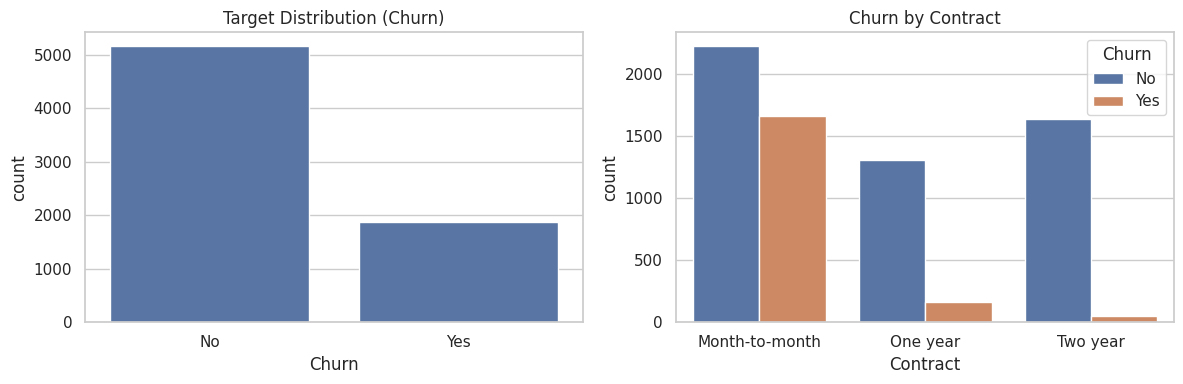

Churn counts:
 Churn
No     5163
Yes    1869
Name: count, dtype: int64

Churn rate (%):
 Churn
No     73.42
Yes    26.58
Name: proportion, dtype: float64

Month-to-month Churn count: 1655


In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(data=df, x="Churn", ax=axes[0])
axes[0].set_title("Target Distribution (Churn)")

sns.countplot(data=df, x="Contract", hue="Churn", ax=axes[1])
axes[1].set_title("Churn by Contract")

plt.tight_layout()
plt.show()

print("Churn counts:\n", df["Churn"].value_counts())
print("\nChurn rate (%):\n", (df["Churn"].value_counts(normalize=True) * 100).round(2))
print("\nMonth-to-month Churn count:", len(df[(df["Contract"] == "Month-to-month") & (df["Churn"] == "Yes")]))

In [16]:
svc_cols = ["OnlineSecurity","OnlineBackup","DeviceProtection",
            "TechSupport","StreamingTV","StreamingMovies"]

n_no_internet = (df["OnlineSecurity"] == "No internet service").sum()
n_no_phone = (df["MultipleLines"] == "No phone service").sum()
n_senior = (df["SeniorCitizen"] == 1).sum()

df[svc_cols] = df[svc_cols].replace("No internet service", "No")
df["MultipleLines"] = df["MultipleLines"].replace("No phone service", "No")
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})
print("Done:", n_no_internet, n_no_phone, n_senior)

Done: 1520 680 1142


### استكشاف البيانات الرسومي (EDA)

في هذه المرحلة قمت باستكشاف البيانات باستخدام الرسوم البيانية لفهم سلوك العملاء بشكل أفضل والتعرف على العوامل المرتبطة بترك الخدمة. من خلال التحليل، لاحظت أن معظم العملاء مستمرون مع الشركة، بينما نسبة أقل منهم قامت بترك الخدمة. كما تبين أن العملاء الذين لديهم **عقود شهرية** كانوا الأكثر عرضة لترك الخدمة مقارنة بالعملاء الذين لديهم عقود سنوية أو طويلة المدة، مما يشير إلى أن نوع العقد قد يكون من العوامل المؤثرة في قرار العميل بالبقاء أو المغادرة.

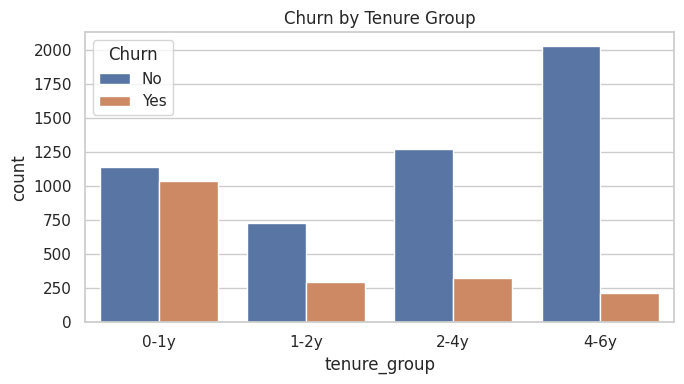

Churn in 0-1y tenure group: 1037
Saved telco_clean.csv with shape: (7032, 23)
Saved telco_model_ready.csv with shape: (7032, 35)


In [15]:
# 1. هندسة خصائص جديدة
df["tenure_group"] = pd.cut(
    df["tenure"],
    bins=[0, 12, 24, 48, 72],
    labels=["0-1y", "1-2y", "2-4y", "4-6y"]
)

df["avg_calculated_charge"] = (df["MonthlyCharges"] * df["tenure"]).round(2)

# رسمة لتوزيع التسرب حسب فئة مدة الاشتراك
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="tenure_group", hue="Churn")
plt.title("Churn by Tenure Group")
plt.tight_layout()
plt.show()

print("Churn in 0-1y tenure group:", len(df[(df["tenure_group"] == "0-1y") & (df["Churn"] == "Yes")]))

# 2. حفظ الداتا النظيفة
df.to_csv("telco_clean.csv", index=False)

# 3. Feature Selection وتجهيز داتا الموديل (استبعاد customerID وتحويل الأعمدة الفئوية)
df_model = pd.get_dummies(df.drop(columns=["customerID"]), drop_first=True)
df_model.to_csv("telco_model_ready.csv", index=False)

print("Saved telco_clean.csv with shape:", df.shape)
print("Saved telco_model_ready.csv with shape:", df_model.shape)

### هندسة الخصائص واختيارها

في هذه المرحلة قمت بإضافة بعض الأعمدة الجديدة للمساعدة في فهم البيانات بشكل أفضل، مثل **تصنيف مدة اشتراك العميل إلى فئات** وحساب **الرسوم المتوقعة** بناءً على مدة الاشتراك والرسوم الشهرية. ومن خلال التحليل لاحظت أن العملاء الجدد كانوا أكثر عرضة لترك الخدمة مقارنة بالعملاء الذين استمروا لفترات أطول.

بعد ذلك قمت بحذف عمود **رقم العميل** لأنه لا يفيد في التحليل، وتحويل البيانات النصية إلى أرقام حتى تصبح مناسبة للاستخدام في بناء نماذج التنبؤ. وأخيرًا تم حفظ البيانات بعد تنظيفها وتجهيزها للاستخدام في المراحل التالية من المشروع.

In [30]:
def churn_rate(col):
    return df.groupby(col, observed=False)["Churn"].apply(lambda s: (s == "Yes").mean() * 100)

g = churn_rate("gender")
p = churn_rate("PhoneService")
c = churn_rate("Contract")
t = churn_rate("tenure_group")

total_num = pd.to_numeric(df["TotalCharges"], errors="coerce")
corr_total_tenure = round(total_num.corr(df["tenure"]), 3)

fs = pd.DataFrame([
    ["customerID", "حذف", "معرّف فريد لكل عميل ولا يفيد التنبؤ"],
    ["gender", "حذف", f"الفرق بين الجنسين: {abs(g.max() - g.min()):.2f}%"],
    ["PhoneService", "حذف", f"الفرق: {abs(p.max() - p.min()):.2f}%"],
    ["TotalCharges", "حذف", f"ارتباطه مع tenure يساوي {corr_total_tenure}"],
    ["Contract", "إبقاء", f"أقل معدل مغادرة: {c.min():.2f}% مقابل الأعلى: {c.max():.2f}%"],
    ["tenure_group", "إبقاء", f"أقل معدل مغادرة: {t.min():.2f}% مقابل الأعلى: {t.max():.2f}%"],
    ["avg_monthly / services_count", "إبقاء", "خصائص مشتقة ذات دلالة تشغيلية"]
], columns=["العمود", "القرار", "الدليل"])

display(fs)

,العمود,القرار,الدليل
0,customerID,حذف,معرّف فريد لكل عميل ولا يفيد التنبؤ
1,gender,حذف,الفرق بين الجنسين: 0.75%
2,PhoneService,حذف,الفرق: 1.75%
3,TotalCharges,حذف,ارتباطه مع tenure يساوي 0.826
4,Contract,إبقاء,أقل معدل مغادرة: 2.85% مقابل الأعلى: 42.71%
5,tenure_group,إبقاء,أقل معدل مغادرة: 9.51% مقابل الأعلى: 47.68%
6,avg_monthly / services_count,إبقاء,خصائص مشتقة ذات دلالة تشغيلية


## اختيار الخصائص (Feature Selection)

اعتمدتُ في كل قرار على رقم من البيانات، وبنيتُ الملف الجاهز للموديل `telco_model_ready.csv` بعد تطبيقها.

**الأعمدة المحذوفة:**
- **customerID:** معرّف فريد لكل عميل (7032 قيمة مختلفة)، فلا يفيد التنبؤ.
- **gender:** الفرق في نسبة المغادرة بين الجنسين 0.75% فقط، فلا يؤثر على قرار العميل.
- **PhoneService:** الفرق في نسبة المغادرة بين من لديه الخدمة ومن لا 1.75% فقط.
- **TotalCharges:** ارتباطه مع tenure يساوي 0.826، فهو يكرر معلومة موجودة في tenure وMonthlyCharges.

**الأعمدة المُبقاة:**
- **Contract:** نسبة المغادرة تتراوح من 2.85% (العقد الطويل) إلى 42.71% (العقد الشهري)، وهو من أقوى المؤشرات.
- **tenure_group:** تتراوح من 9.51% إلى 47.68%، وأعلى فئة فقدًا هي أول سنة.
- **services_count:** عمود جديد يعد خدمات العميل، ويتغير معدل المغادرة بتغير عددها.

**تجهيز الداتا للموديل:** حوّلتُ Churn إلى 0/1، وحوّلتُ الأعمدة النصية إلى أرقام بـ get_dummies، وحفظتُ النتيجة في `telco_model_ready.csv`. ولم أستخدم Churn في أي تعبئة أو حساب للأعمدة المدخلة، حتى لا يحدث تسريب للـ Target.

## النتائج والتوصيات
**ماذا اكتشفت:** نسبة الفقد العامة 26.6%. العقد الشهري أعلى فئة فقدًا بنسبة 42.7%، وأول سنة اشتراك أعلى فترة بنسبة 47.7% (1037 عميلًا غادروا).

**التوصية لإدارة التسويق في شركة الاتصالات:** تقديم خصم أو مزايا للعملاء الجدد مقابل التحويل إلى عقد سنوي خلال أول 12 شهرًا، لأن حوالي نصف عملاء هذه الفترة يغادرون.

## تقرير الأسبوع

**مقارنة المشروعين:** أصعب مشكلة في داتا السكري كانت الأصفار المخفية: أعمدة مثل Insulin (374 صفًا) وSkinThickness (227 صفًا) فيها أصفار مستحيلة طبيًا، وهي قيم مفقودة لم يكشفها isnull()، وتعويضها كان قرارًا صعبًا لأنها تقارب نصف الصفوف في الأنسولين. وتعلمت أن التعويض بوسيط كل فئة من Outcome تسريب للـ Target ويضخّم الارتباطات (ارتفع ارتباط Insulin من 0.13 إلى 0.38)، فالصحيح استخدام وسيط العمود كاملًا. وفي داتا العملاء كانت المشكلة في عمود TotalCharges لأنه نصي وفيه 11 قيمة فارغة مخفية، وظهرت بفحص المسافات الفارغة. الأصعب عليّ كانت داتا السكري، لأن قرارات التعويض فيها تؤثر على النتائج، بينما في داتا العملاء كانت 11 صفًا فقط (0.16%) فكان حذفها قرارًا بسيطًا.

**أفضل رسمة هذا الأسبوع:** رسمة Churn by Contract في مشروع العملاء، لأنها أظهرت بنظرة واحدة أن العقد الشهري أعلى فئة فقدًا بنسبة 42.71%، بينما العقد الطويل أقل بكثير (2.85%). وهي بسيطة وواضحة حتى لمن لا يعرف التحليل، وحوّلتُها إلى رسمة تفاعلية في الـ Dashboard.

**ما سأفعله أسرع الآن، وما زال صعبًا:** أبدأ من أول يوم بفحص الأنواع والقيم الفارغة المخفية قبل أي تحليل، ولا أستخدم عمود الهدف في أي تعبئة أو تحويل، وأوثّق كل قرار تنظيف برقمه وعدد الصفوف المتأثرة، وأشغّل الدفتر كاملًا من البداية قبل التسليم. وما زال صعبًا عليّ اختيار الأعمدة المناسبة للموديل وتفسير الارتباطات بينها، لأن القرار يحتاج دليلًا بالأرقام وليس مجرد إحساس.

**توصية لشركة الاتصالات:** التركيز على عملاء أول سنة اشتراك، إذ غادر 47.68% منهم (1037 عميلًا)، وهي أعلى فئة خطرًا في تحليلي. أقترح على إدارة التسويق تقديم خصم أو مزايا لهم مقابل التحويل إلى عقد سنوي خلال أول 12 شهرًا، لأن العقد الشهري يغادر منه 42.71% مقابل 2.85% فقط في العقد الطويل.